In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
data = {
    'Sampel': ['A', 'B', 'C'],
    'Diameter_X1': [4, 8, 6],
    'Berat_X2': [8, 12, 10]
}

df = pd.DataFrame(data)
print(df.to_string(index=False))

Sampel  Diameter_X1  Berat_X2
     A            4         8
     B            8        12
     C            6        10


In [16]:
X = df[['Diameter_X1', 'Berat_X2']].values

mean_X1 = np.mean(X[:, 0])
mean_X2 = np.mean(X[:, 1])

print(f'Mean X1 (Diameter) = {mean_X1}')
print(f'Mean X2 (Berat)    = {mean_X2}')

Mean X1 (Diameter) = 6.0
Mean X2 (Berat)    = 10.0


In [ ]:
mean_vec = np.array([mean_X1, mean_X2])
X_centered = X - mean_vec

df_centered = pd.DataFrame(
    X_centered,
    columns=['X1_centered', 'X2_centered'],
    index=['A', 'B', 'C']
)
print(df_centered)

   X1_centered  X2_centered
A         -2.0         -2.0
B          2.0          2.0
C          0.0          0.0


In [18]:
cov_matrix = np.cov(X_centered.T, ddof=1)

print('Matriks Kovarians:')
print(f'  Cov(X1,X1) = {cov_matrix[0,0]:.4f}')
print(f'  Cov(X1,X2) = {cov_matrix[0,1]:.4f}')
print(f'  Cov(X2,X1) = {cov_matrix[1,0]:.4f}')
print(f'  Cov(X2,X2) = {cov_matrix[1,1]:.4f}')
print()
print(cov_matrix)

Matriks Kovarians:
  Cov(X1,X1) = 4.0000
  Cov(X1,X2) = 4.0000
  Cov(X2,X1) = 4.0000
  Cov(X2,X2) = 4.0000

[[4. 4.]
 [4. 4.]]


In [ ]:
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

sorted_idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_idx]
eigenvectors = eigenvectors[:, sorted_idx]

print('Eigenvalue:')
for i, val in enumerate(eigenvalues):
    print(f'  Lambda{i+1} = {val:.4f}')

print()
print('Eigenvector:')
for i in range(eigenvectors.shape[1]):
    print(f'  PC{i+1}: {eigenvectors[:, i]}')

Eigenvalue:
  Lambda1 = 8.0000
  Lambda2 = 0.0000

Eigenvector:
  PC1: [0.70710678 0.70710678]
  PC2: [-0.70710678  0.70710678]


In [20]:
total_variance = np.sum(eigenvalues)
explained_variance_ratio = eigenvalues / total_variance

print('Rasio Variansi:')
for i, ratio in enumerate(explained_variance_ratio):
    print(f'  PC{i+1}: {ratio:.4f} ({ratio*100:.2f}%)')



Rasio Variansi:
  PC1: 1.0000 (100.00%)
  PC2: 0.0000 (0.00%)


In [21]:
pc1 = eigenvectors[:, 0]
print(f'Eigenvector PC1: {pc1}')

X_pca = X_centered @ pc1

df_hasil = pd.DataFrame({
    'Sampel': ['A', 'B', 'C'],
    'Diameter_X1': X[:, 0],
    'Berat_X2': X[:, 1],
    'Skor_PC1': X_pca
})

print()
print('Hasil Proyeksi ke PC1:')
print(df_hasil.to_string(index=False))

Eigenvector PC1: [0.70710678 0.70710678]

Hasil Proyeksi ke PC1:
Sampel  Diameter_X1  Berat_X2  Skor_PC1
     A            4         8 -2.828427
     B            8        12  2.828427
     C            6        10  0.000000


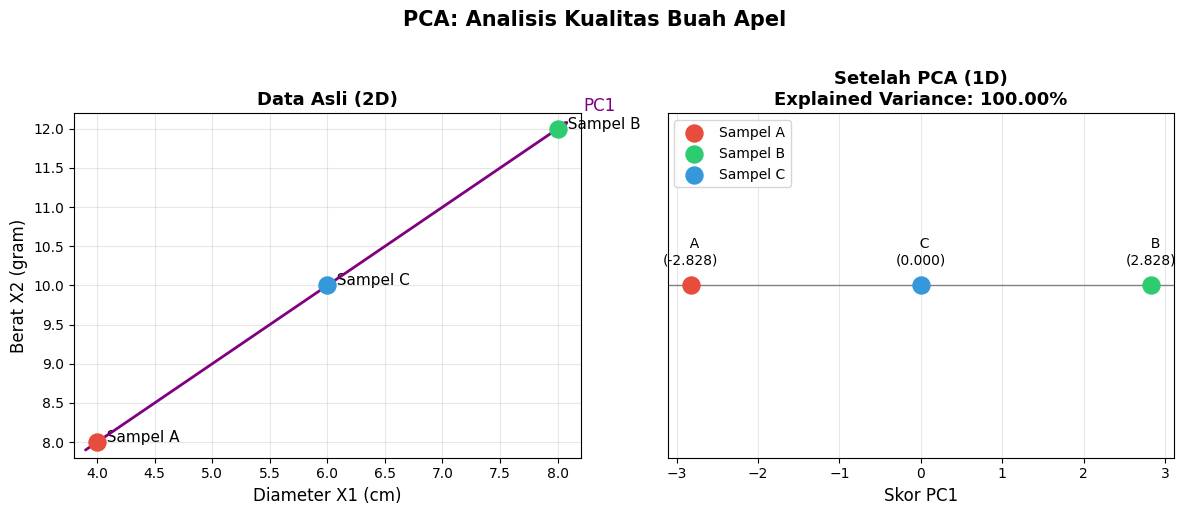

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


ax1 = axes[0]
sampel_labels = ['A', 'B', 'C']
colors = ['#e74c3c', '#2ecc71', '#3498db']
for i, (x1, x2, label) in enumerate(zip(X[:, 0], X[:, 1], sampel_labels)):
    ax1.scatter(x1, x2, color=colors[i], s=150, zorder=5)
    ax1.annotate(f'  Sampel {label}', (x1, x2), fontsize=11)


scale = 3
cx, cy = mean_X1, mean_X2
ax1.annotate('', xy=(cx + scale*pc1[0], cy + scale*pc1[1]),
             xytext=(cx - scale*pc1[0], cy - scale*pc1[1]),
             arrowprops=dict(arrowstyle='->', color='purple', lw=2))
ax1.text(cx + scale*pc1[0]+0.1, cy + scale*pc1[1]+0.1, 'PC1', color='purple', fontsize=12)

ax1.set_xlabel('Diameter X1 (cm)', fontsize=12)
ax1.set_ylabel('Berat X2 (gram)', fontsize=12)
ax1.set_title('Data Asli (2D)', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)

ax2 = axes[1]
for i, (score, label) in enumerate(zip(X_pca, sampel_labels)):
    ax2.scatter(score, 0, color=colors[i], s=150, zorder=5, label=f'Sampel {label}')
    ax2.annotate(f'  {label}\n({score:.3f})', (score, 0), textcoords='offset points',
                 xytext=(0, 15), ha='center', fontsize=10)

ax2.axhline(0, color='gray', linewidth=1)
ax2.set_yticks([])
ax2.set_xlabel('Skor PC1', fontsize=12)
ax2.set_title(f'Setelah PCA (1D)\nExplained Variance: {explained_variance_ratio[0]*100:.2f}%', fontsize=13, fontweight='bold')
ax2.legend(loc='upper left', fontsize=10)
ax2.grid(True, alpha=0.3)

plt.suptitle('PCA: Analisis Kualitas Buah Apel', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()